# Decomposition of proximity data from chromatin tracing

## Example with a simulated dataset

In this example, we will
- load some proximity data, check its qualty and visualize it
- train an LDA model and evaluate its perplexity and coherence
- visualize the results of a trained model

### Visualizing the sample data

Import required modules

In [1]:
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import joblib
import h5py
from scipy.spatial.distance import squareform
from topic3d.datatypes import PWProxArrayStack
from topic3d.handlers import DecompositionResult
from IPython.display import Image

In [8]:
data_train_sim = PWProxArrayStack(np.load("./data/sample_sim_train.npy"))
data_test_sim = PWProxArrayStack(np.load("./data/sample_sim_test.npy"))
data_train_sim.shape, data_test_sim.shape

((1440, 780), (360, 780))

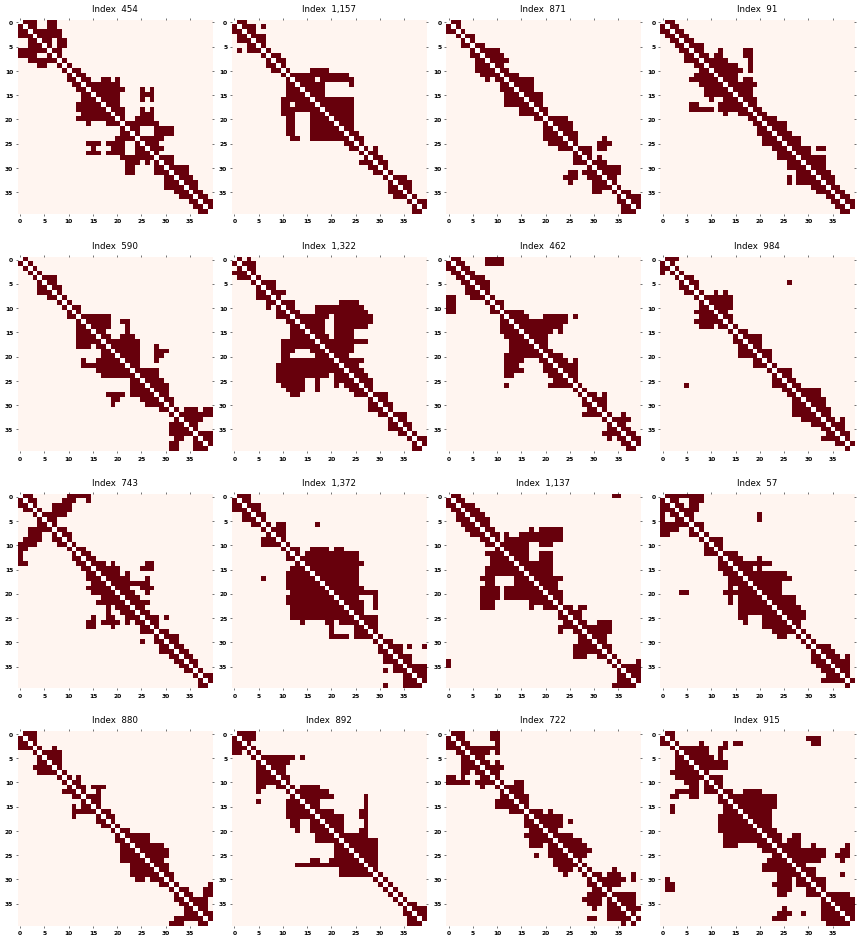

In [ ]:
fig = data_train_sim.plot_random_examples(num_items=16,
                                          random_seed=None,
                                          form="square",
                                          include_cbar=False)
fig.set_dpi(48)
fig.show()

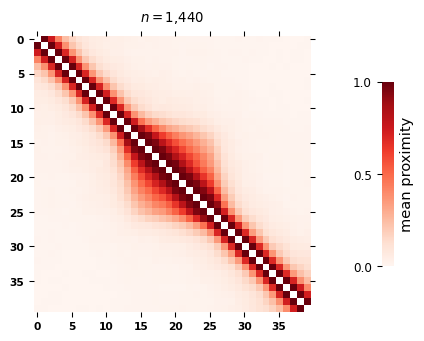

In [10]:
fig = data_train_sim.plot_ensemble_avg(method="mean", form="square", cbar_label="mean proximity")
fig.set_dpi(96)
fig.show()

### Training

Running the following shell script as a subprocess

```bash
topic3d-decompose \
        --data_train_file ./data/sample_sim_train.npy \
        --data_test_file ./data/sample_sim_test.npy \
        --results_dir ./results/ \
        --num_components 4 \
        --max_iter 50 \
        --learning_method "batch" \
        --random_state 64
```

In [ ]:
subprocess.run([
    "topic3d-decompose",
    "--data_train_file", "./data/sample_sim_train.npy",
    "--data_test_file", "./data/sample_sim_test.npy",
    "--results_dir", "./results/",
    "--num_components", "4",
    "--max_iter", "50",
    "--learning_method", "batch",
    "--random_state", "64",
])

2026-02-23 17:16:48,516 [INFO] --------------------------------------------------
2026-02-23 17:16:48,516 [INFO] [e888c5] Will save trainings to: ./results/e888c5
2026-02-23 17:16:48,516 [INFO] Settings summary for run: e888c5
2026-02-23 17:16:48,516 [INFO]     data_train_file: ./data/sample_sim_train.npy
2026-02-23 17:16:48,516 [INFO]     data_test_file: ./data/sample_sim_test.npy
2026-02-23 17:16:48,517 [INFO]     results_dir: ./results/
2026-02-23 17:16:48,517 [INFO]     num_components: 4
2026-02-23 17:16:48,517 [INFO]     max_iter: 50
2026-02-23 17:16:48,517 [INFO]     learning_method: batch
2026-02-23 17:16:48,517 [INFO]     batch_size: 64
2026-02-23 17:16:48,517 [INFO]     random_state: 64
2026-02-23 17:16:48,517 [INFO]     uid: e888c5
2026-02-23 17:16:48,517 [INFO]     path_to_data: ['./data/sample_sim_train.npy', './data/sample_sim_test.npy']
2026-02-23 17:16:48,517 [INFO]     path_to_training: ./results/e888c5
2026-02-23 17:16:48,517 [INFO]     path_to_log: ./results/e888c5/lo

CompletedProcess(args=['topic3d-decompose', '--data_train_file', './data/sample_sim_train.npy', '--data_test_file', './data/sample_sim_test.npy', '--results_dir', './results/', '--num_components', '4', '--max_iter', '50', '--learning_method', 'batch', '--random_state', '64'], returncode=0)

We can check the model's perplexity on the training set (first code block below) and on the training set.

In [17]:
# On the training dataset
model = joblib.load(filename="./results/e888c5/model_lda.jl")
model.bound_

np.float64(280.2184231458968)

In [18]:
# On the testing dataset (approx.)
model.perplexity(data_test_sim)

np.float64(312.0495216544464)

### Results

Loading them using `DecompositionResult` for faster access of results and plotting. We need the function below to recursively access data from the saved HDF5 group

In [19]:
def hdf5_group_to_dict(h5obj):
    """
    Recursively convert an HDF5 group or file into a nested Python dictionary.

    Parameters
    ----------
    h5obj : h5py.Group or h5py.File
        HDF5 object to convert.

    Returns
    -------
    dict
        Nested dictionary representation of the HDF5 structure.
    """

    out = {}

    # Add attributes (if any)
    if hasattr(h5obj, "attrs") and len(h5obj.attrs) > 0:
        out["_attrs"] = {k: v for k, v in h5obj.attrs.items()}

    for key, item in h5obj.items():

        # If subgroup → recurse
        if isinstance(item, h5py.Group):
            out[key] = hdf5_group_to_dict(item)

        # If dataset → extract data
        elif isinstance(item, h5py.Dataset):
            data = item[()]

            # Convert bytes to string if needed
            if isinstance(data, bytes):
                data = data.decode("utf-8")

            # Convert scalar numpy types to Python types
            if isinstance(data, np.generic):
                data = data.item()

            out[key] = data

    return out

In [20]:
with h5py.File("./results/e888c5/results.h5", mode="r") as handler:
    decomposition = handler["decomposition"][:]
    coherence = hdf5_group_to_dict(handler["coherence"])
results_sim = DecompositionResult(model=model, decomposition=decomposition)

The Normalized Pointwise Mutual Information coherence for each component of this trained model with the training data, taking different top `npx` pixels, would be:

In [21]:
coherence["npmi"].keys()

dict_keys(['10', '2.5', '5', '7.5'])

In [25]:
coherence["npmi"]["2.5"]

array([-0.52577687,  0.26507357,  0.32982408,  0.22816055])

The normalized between [-1,+1] resulting in -1 (in the limit) for never occurring together, 0 for independence, and +1 for complete co-occurrence.

Plotting the components from the training data shows latent proximity co-occurrence patterns. In this case, since the only two ingredients of our polymer simulation are the usual polymer connectivity and the domain in the middle, they are the ones with high representativity in the dataset.

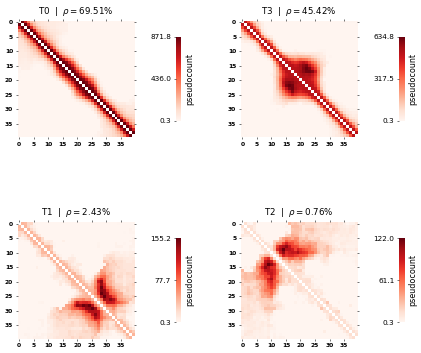

In [26]:
fig = results_sim.plot_components(ordered=True, form="square")
fig.set_dpi(48)
fig.show()

The divergence between the components must generally be high

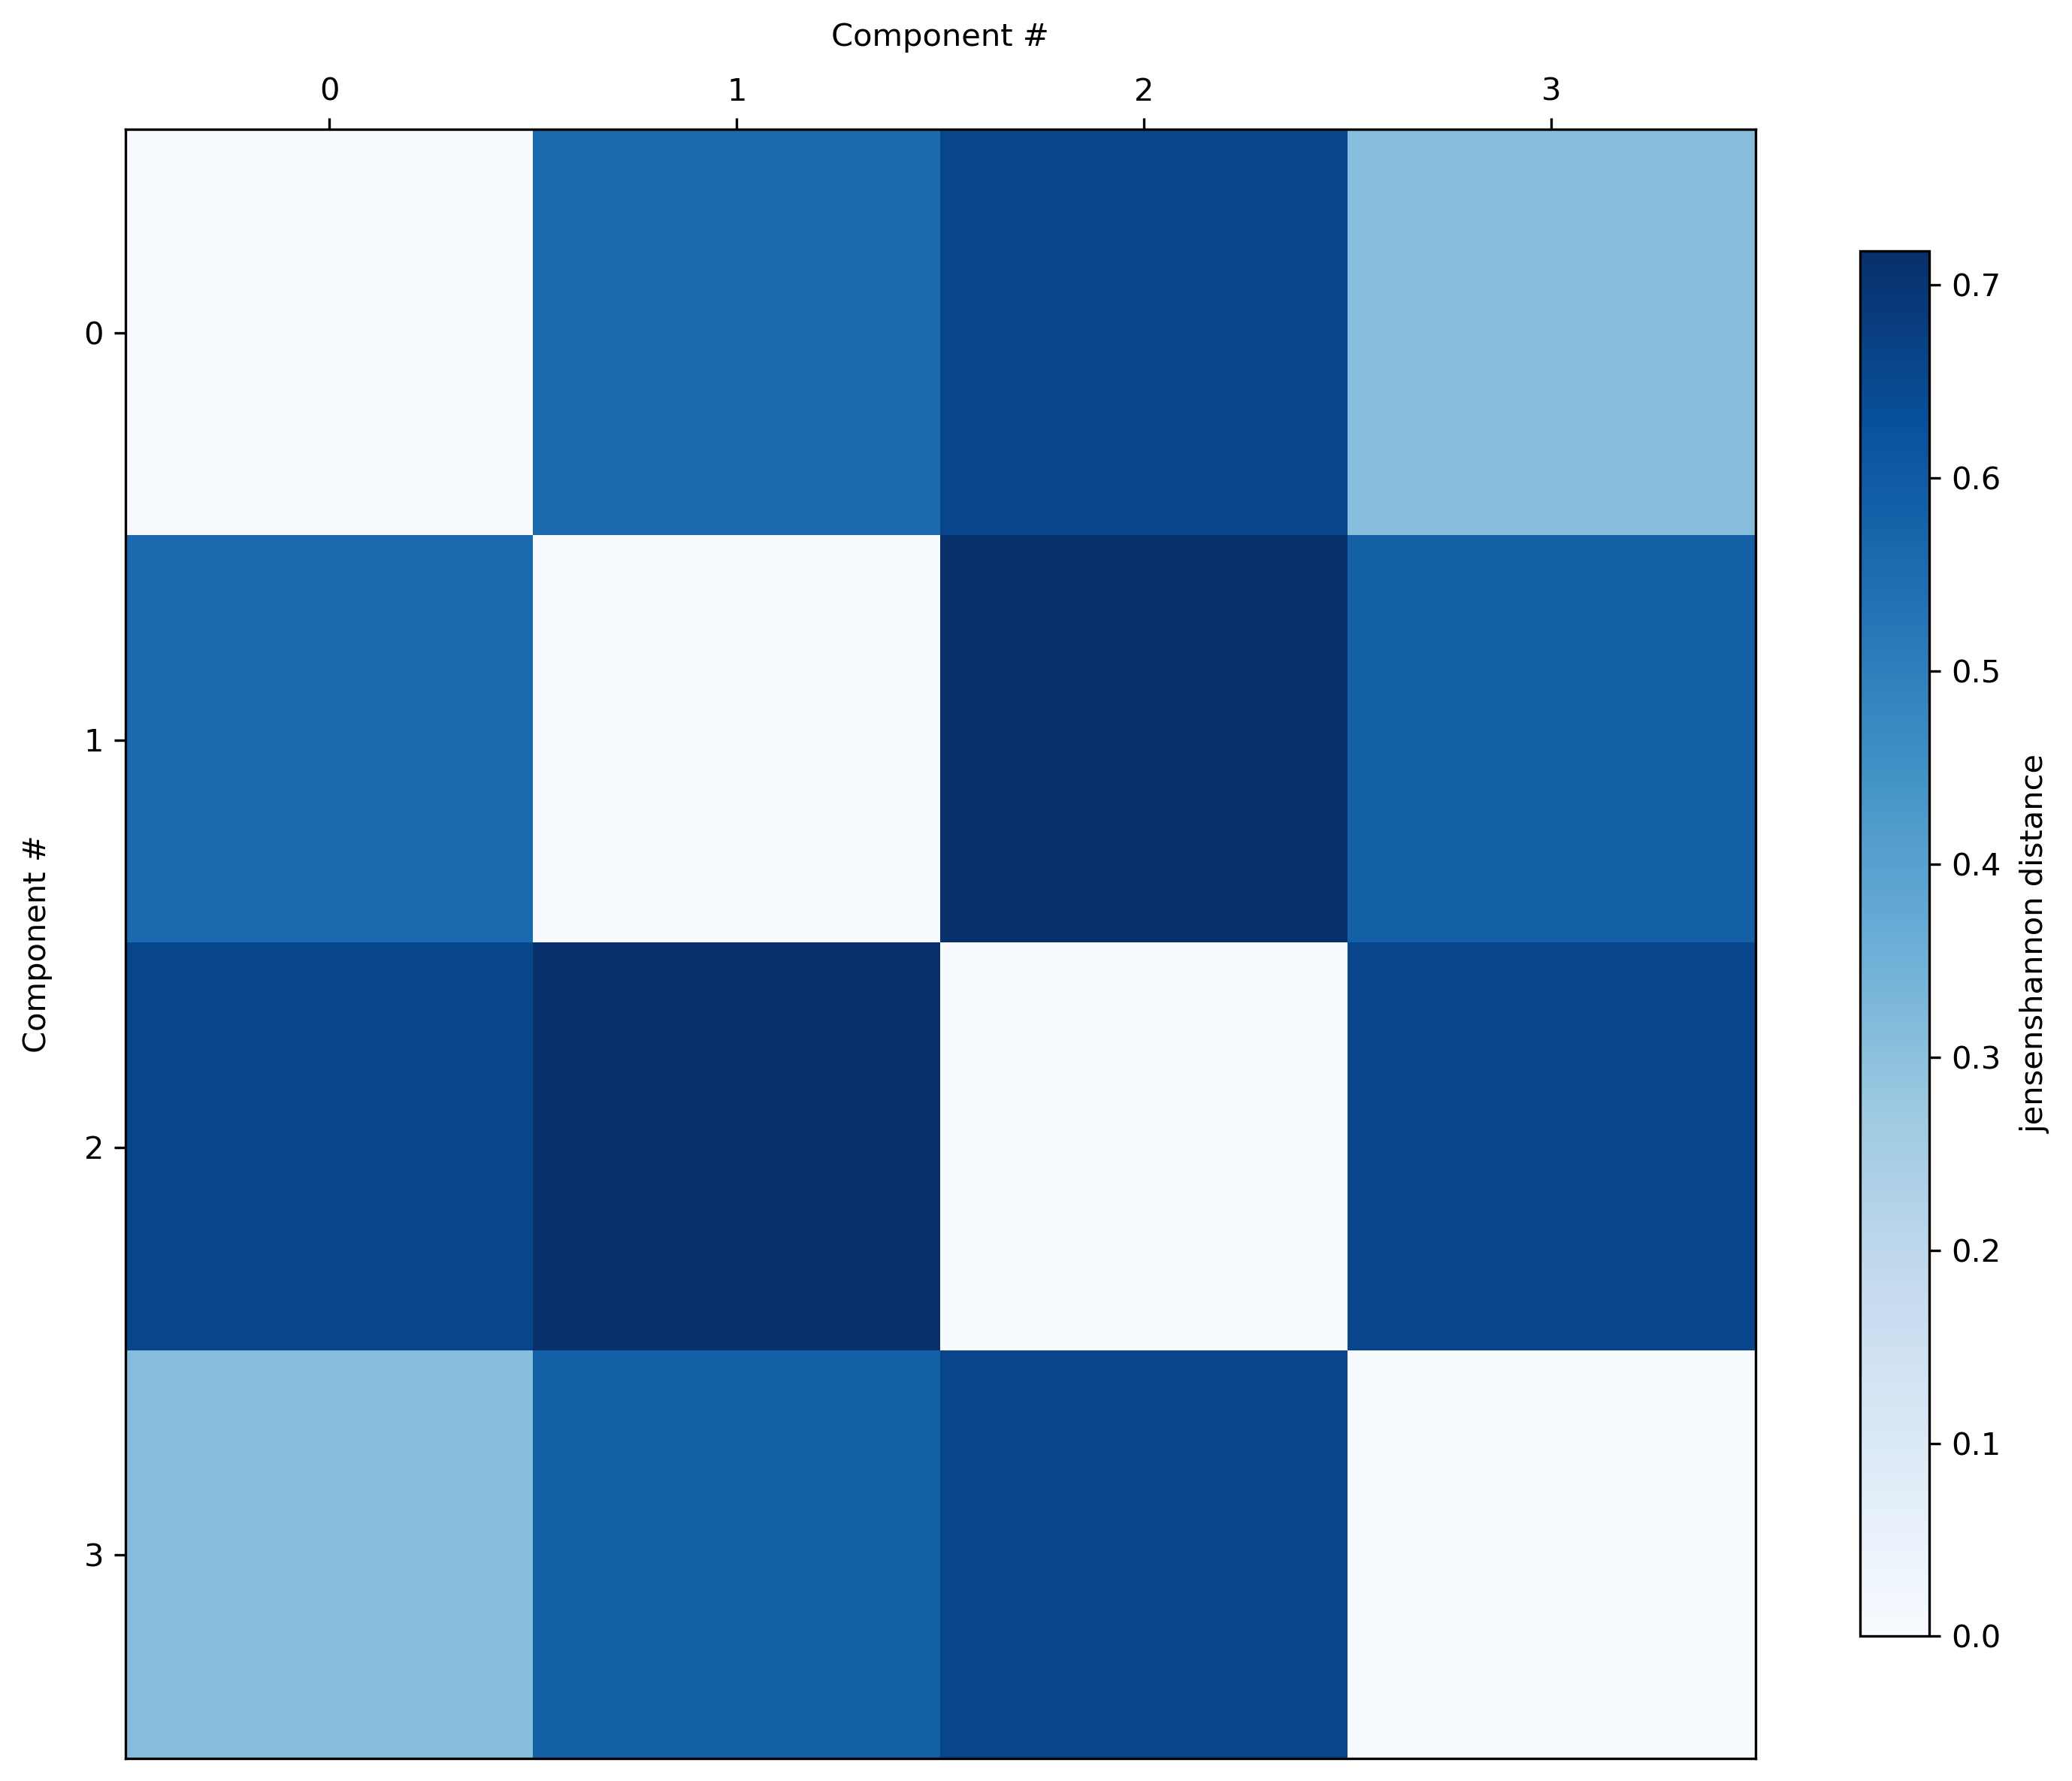

In [29]:
results_sim.divergence(metric="jensenshannon", path_to_save="./results/e888c5/components_divergence.png")
Image(filename="./results/e888c5/components_divergence.png", width=600, height=550)

And the corresponding decomposition matrix

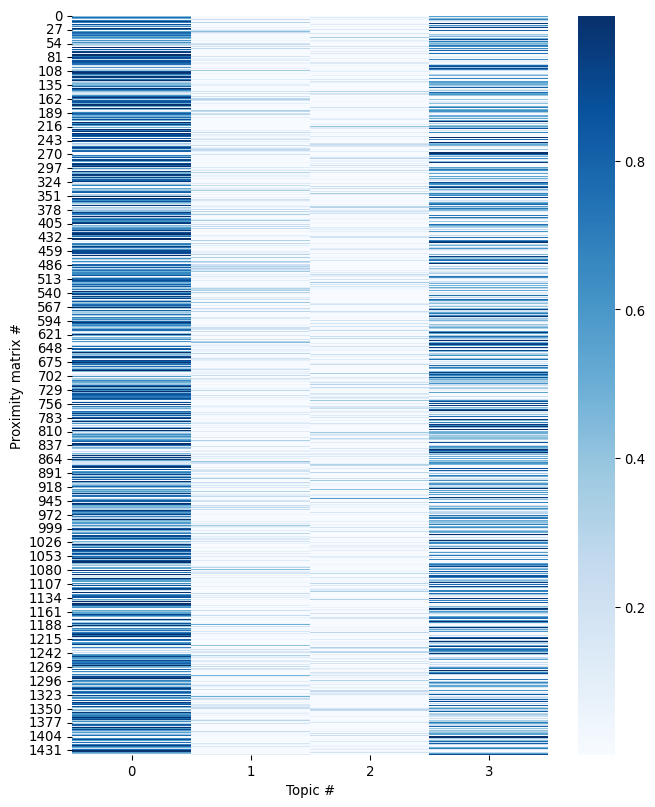

In [30]:
fig = results_sim.plot_decomposition(ordered=False)
fig.set_dpi(96)
fig.show()

## Example with experimental dataset

In contrast to our simulated dataset above, experimental ones are much more complex and also have low probe detection efficiencies. We can still use this to find meaningful information as long as proximity co-occurrence patterns exist latent in the data. For an example, here, we use a part of the tracing data from Bintu & Chen *et al.*, 2018, where we have an existing model

In [2]:
data_test_exp = PWProxArrayStack(np.load("./data/sample_exp_test.npy"))
data_test_exp.shape

(582, 946)

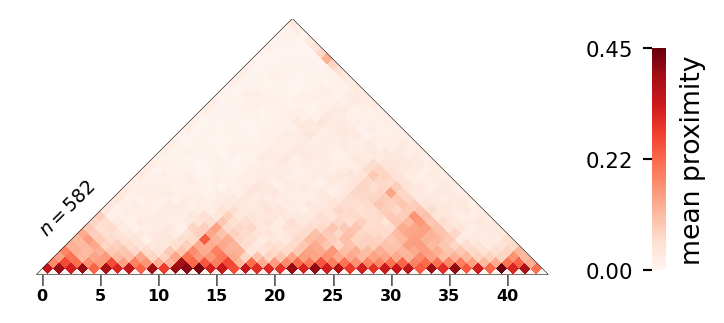

In [3]:
fig = data_test_exp.plot_ensemble_avg(method="mean", form="triangle", cbar_label="mean proximity")
fig.set_dpi(192)
fig.show()

Here, we will fit to and decompose the training data itself, using the test data only for checking perplexity

```bash
topic3d-decompose \
        --data_train_file ./data/sample_exp_train.npy \
        --results_dir ./results/ \
        --num_components 15 \
        --max_iter 250 \
        --learning_method "batch" \
        --random_state 42
```

In [4]:
# subprocess.run([
#     "topic3d-decompose",
#     "--data_train_file", "./data/sample_exp_train.npy",
#     "--results_dir", "./results/",
#     "--num_components", "15",
#     "--max_iter", "200",
#     "--learning_method", "batch",
#     "--random_state", "42",
# ])

In [5]:
subprocess.run([
    "topic3d-decompose",
    "--data_test_file", "./data/sample_exp_test.npy",
    "--model_file", "./results/10d822/model_lda.jl",
    "--results_dir", "./results/",
    "--num_components", "15",
    "--max_iter", "200",
    "--learning_method", "batch",
    "--random_state", "42",
])

2026-02-23 19:55:12,993 [INFO] --------------------------------------------------
2026-02-23 19:55:12,994 [INFO] [2c567b] Will save trainings to: ./results/2c567b
2026-02-23 19:55:12,994 [INFO] Settings summary for run: 2c567b
2026-02-23 19:55:12,994 [INFO]     data_train_file: None
2026-02-23 19:55:12,994 [INFO]     data_test_file: ./data/sample_exp_test.npy
2026-02-23 19:55:12,994 [INFO]     model_file: ./results/10d822/model_lda.jl
2026-02-23 19:55:12,994 [INFO]     results_dir: ./results/
2026-02-23 19:55:12,994 [INFO]     num_components: 15
2026-02-23 19:55:12,994 [INFO]     max_iter: 200
2026-02-23 19:55:12,994 [INFO]     learning_method: batch
2026-02-23 19:55:12,994 [INFO]     batch_size: 64
2026-02-23 19:55:12,994 [INFO]     random_state: 42
2026-02-23 19:55:12,995 [INFO]     uid: 2c567b
2026-02-23 19:55:12,995 [INFO]     path_to_data: [None, './data/sample_exp_test.npy']
2026-02-23 19:55:12,995 [INFO]     path_to_training: ./results/2c567b
2026-02-23 19:55:12,995 [INFO]     p

CompletedProcess(args=['topic3d-decompose', '--data_test_file', './data/sample_exp_test.npy', '--model_file', './results/10d822/model_lda.jl', '--results_dir', './results/', '--num_components', '15', '--max_iter', '200', '--learning_method', 'batch', '--random_state', '42'], returncode=0)

In [35]:
model = joblib.load(filename="./results/10d822/model_lda.jl")
model.bound_, model.perplexity(data_test_exp)

(np.float64(591.9236261327932), np.float64(786.6512211007954))

Since the results get saved automatically at the end of the process, we can simply view the components and decomposition matrices.

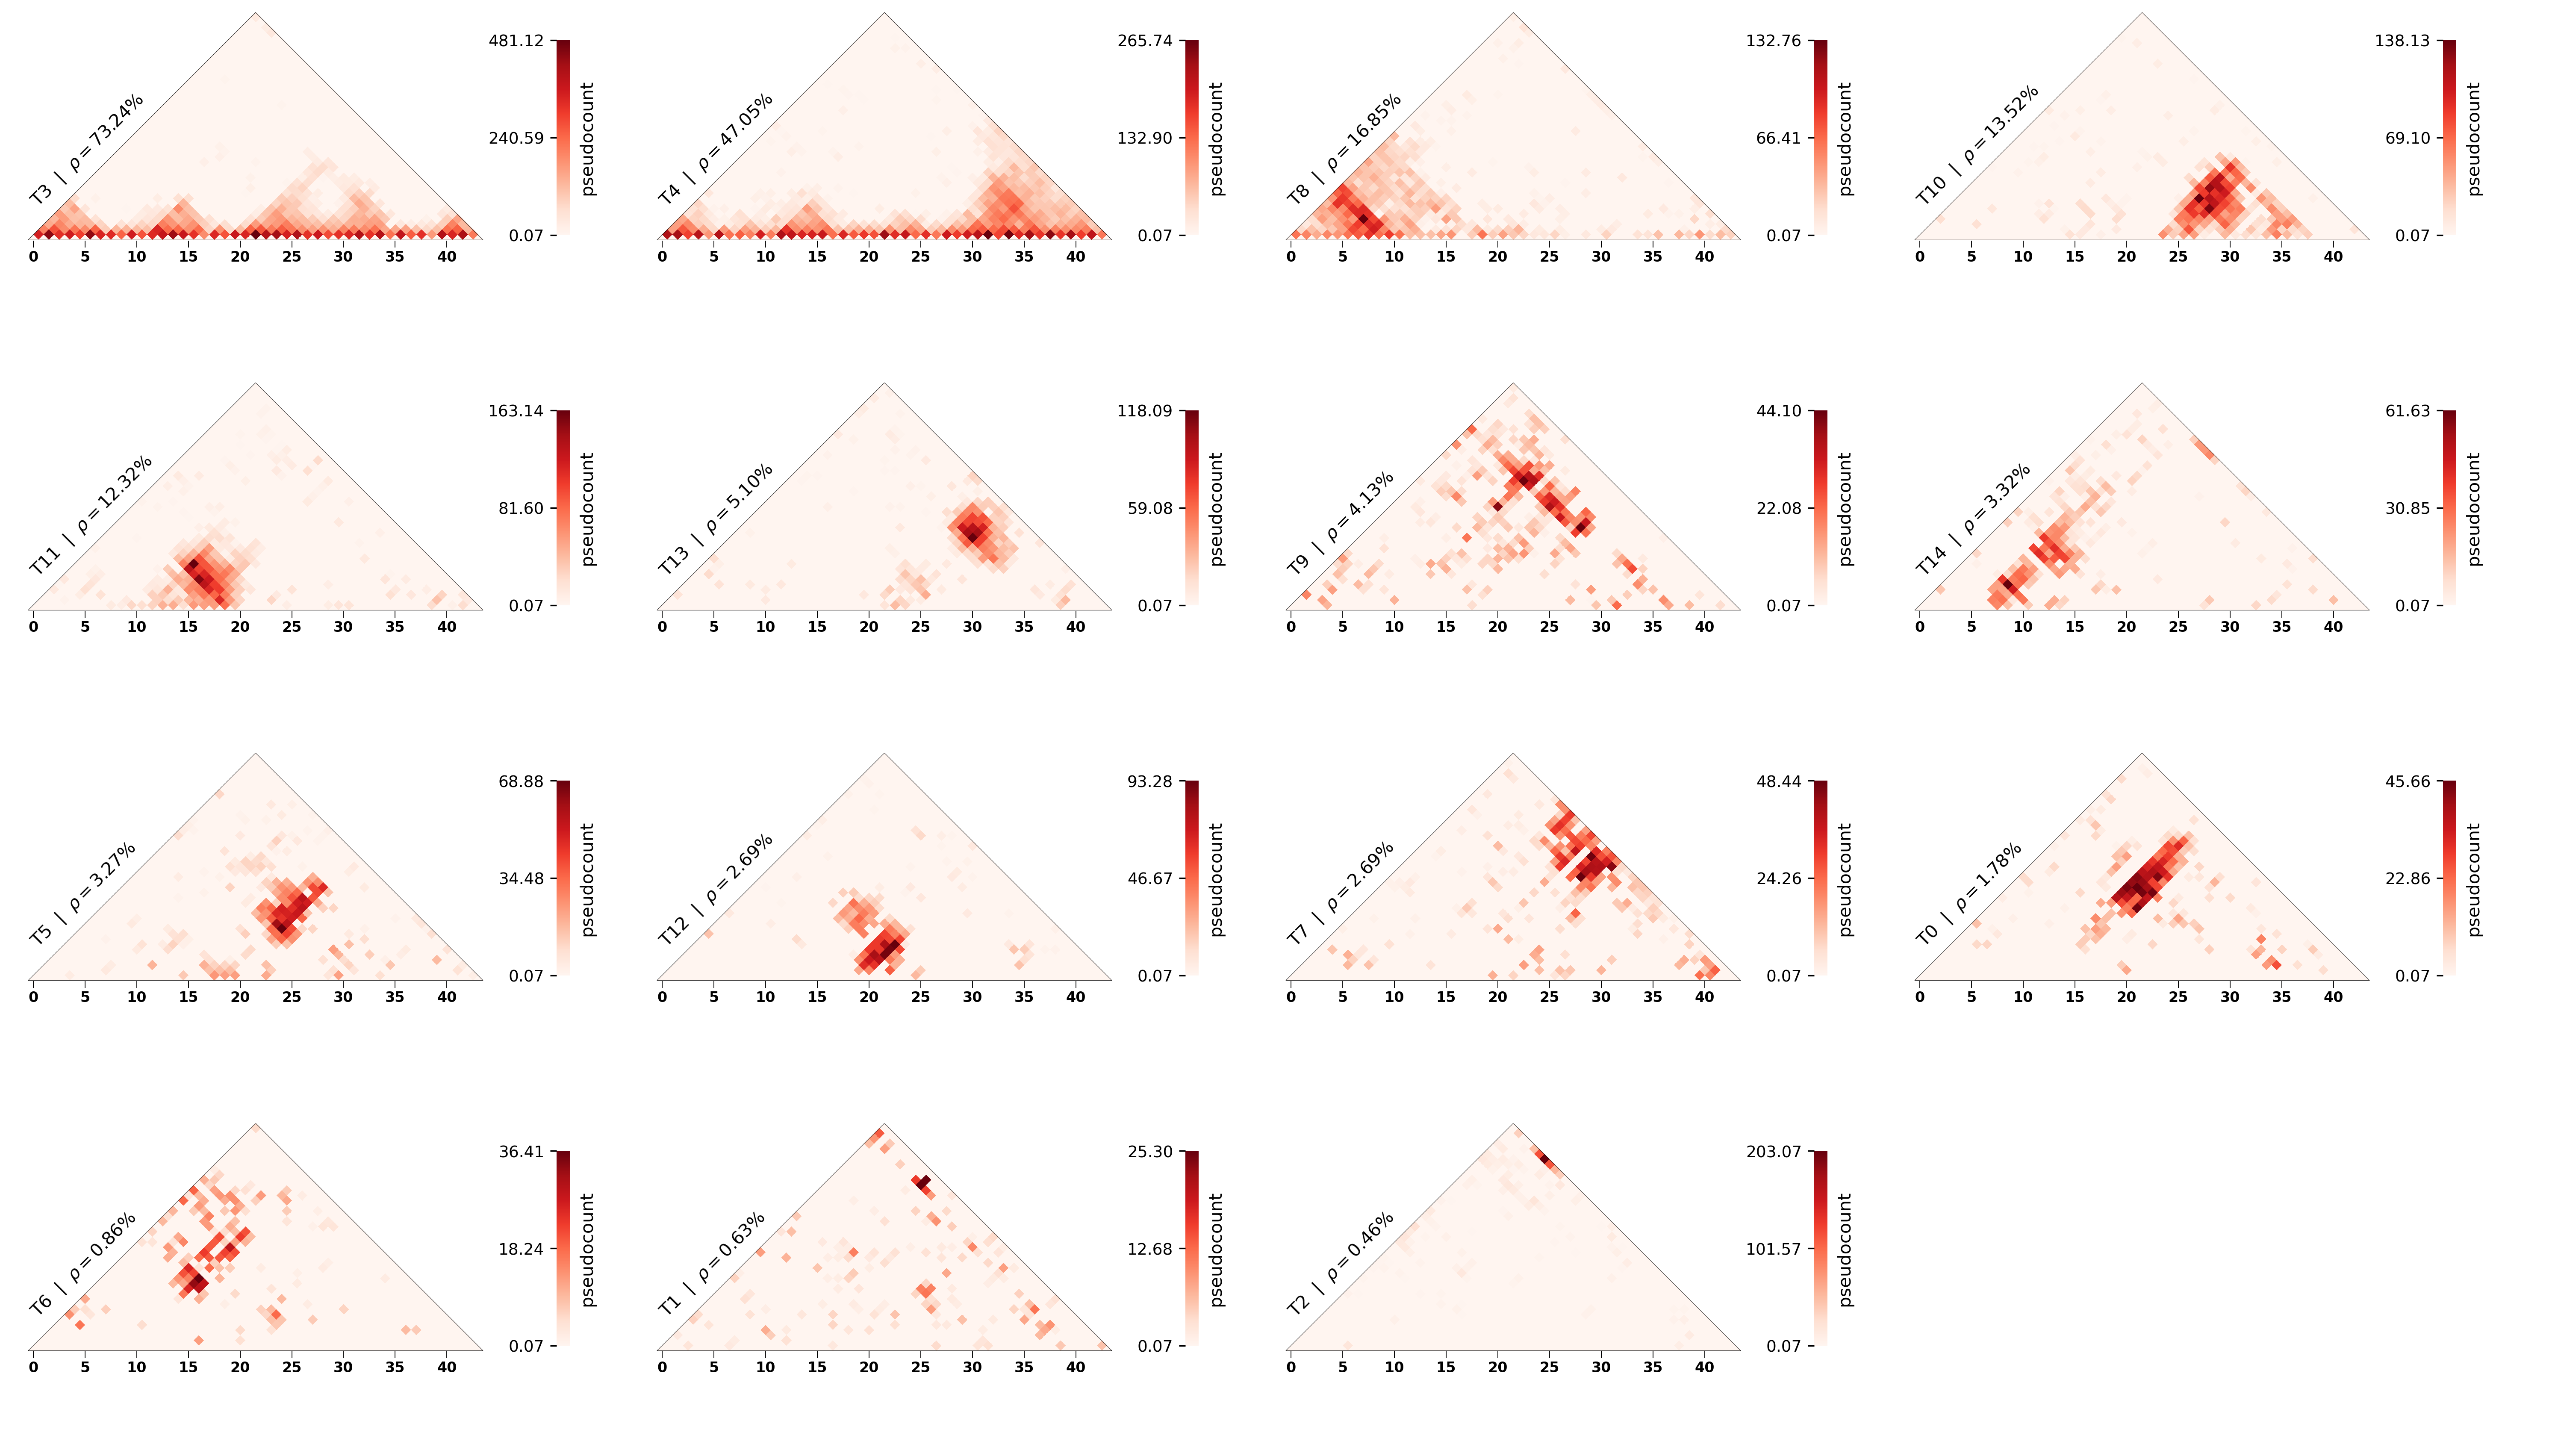

In [36]:
Image(filename="./results/10d822/components_sorted.png")

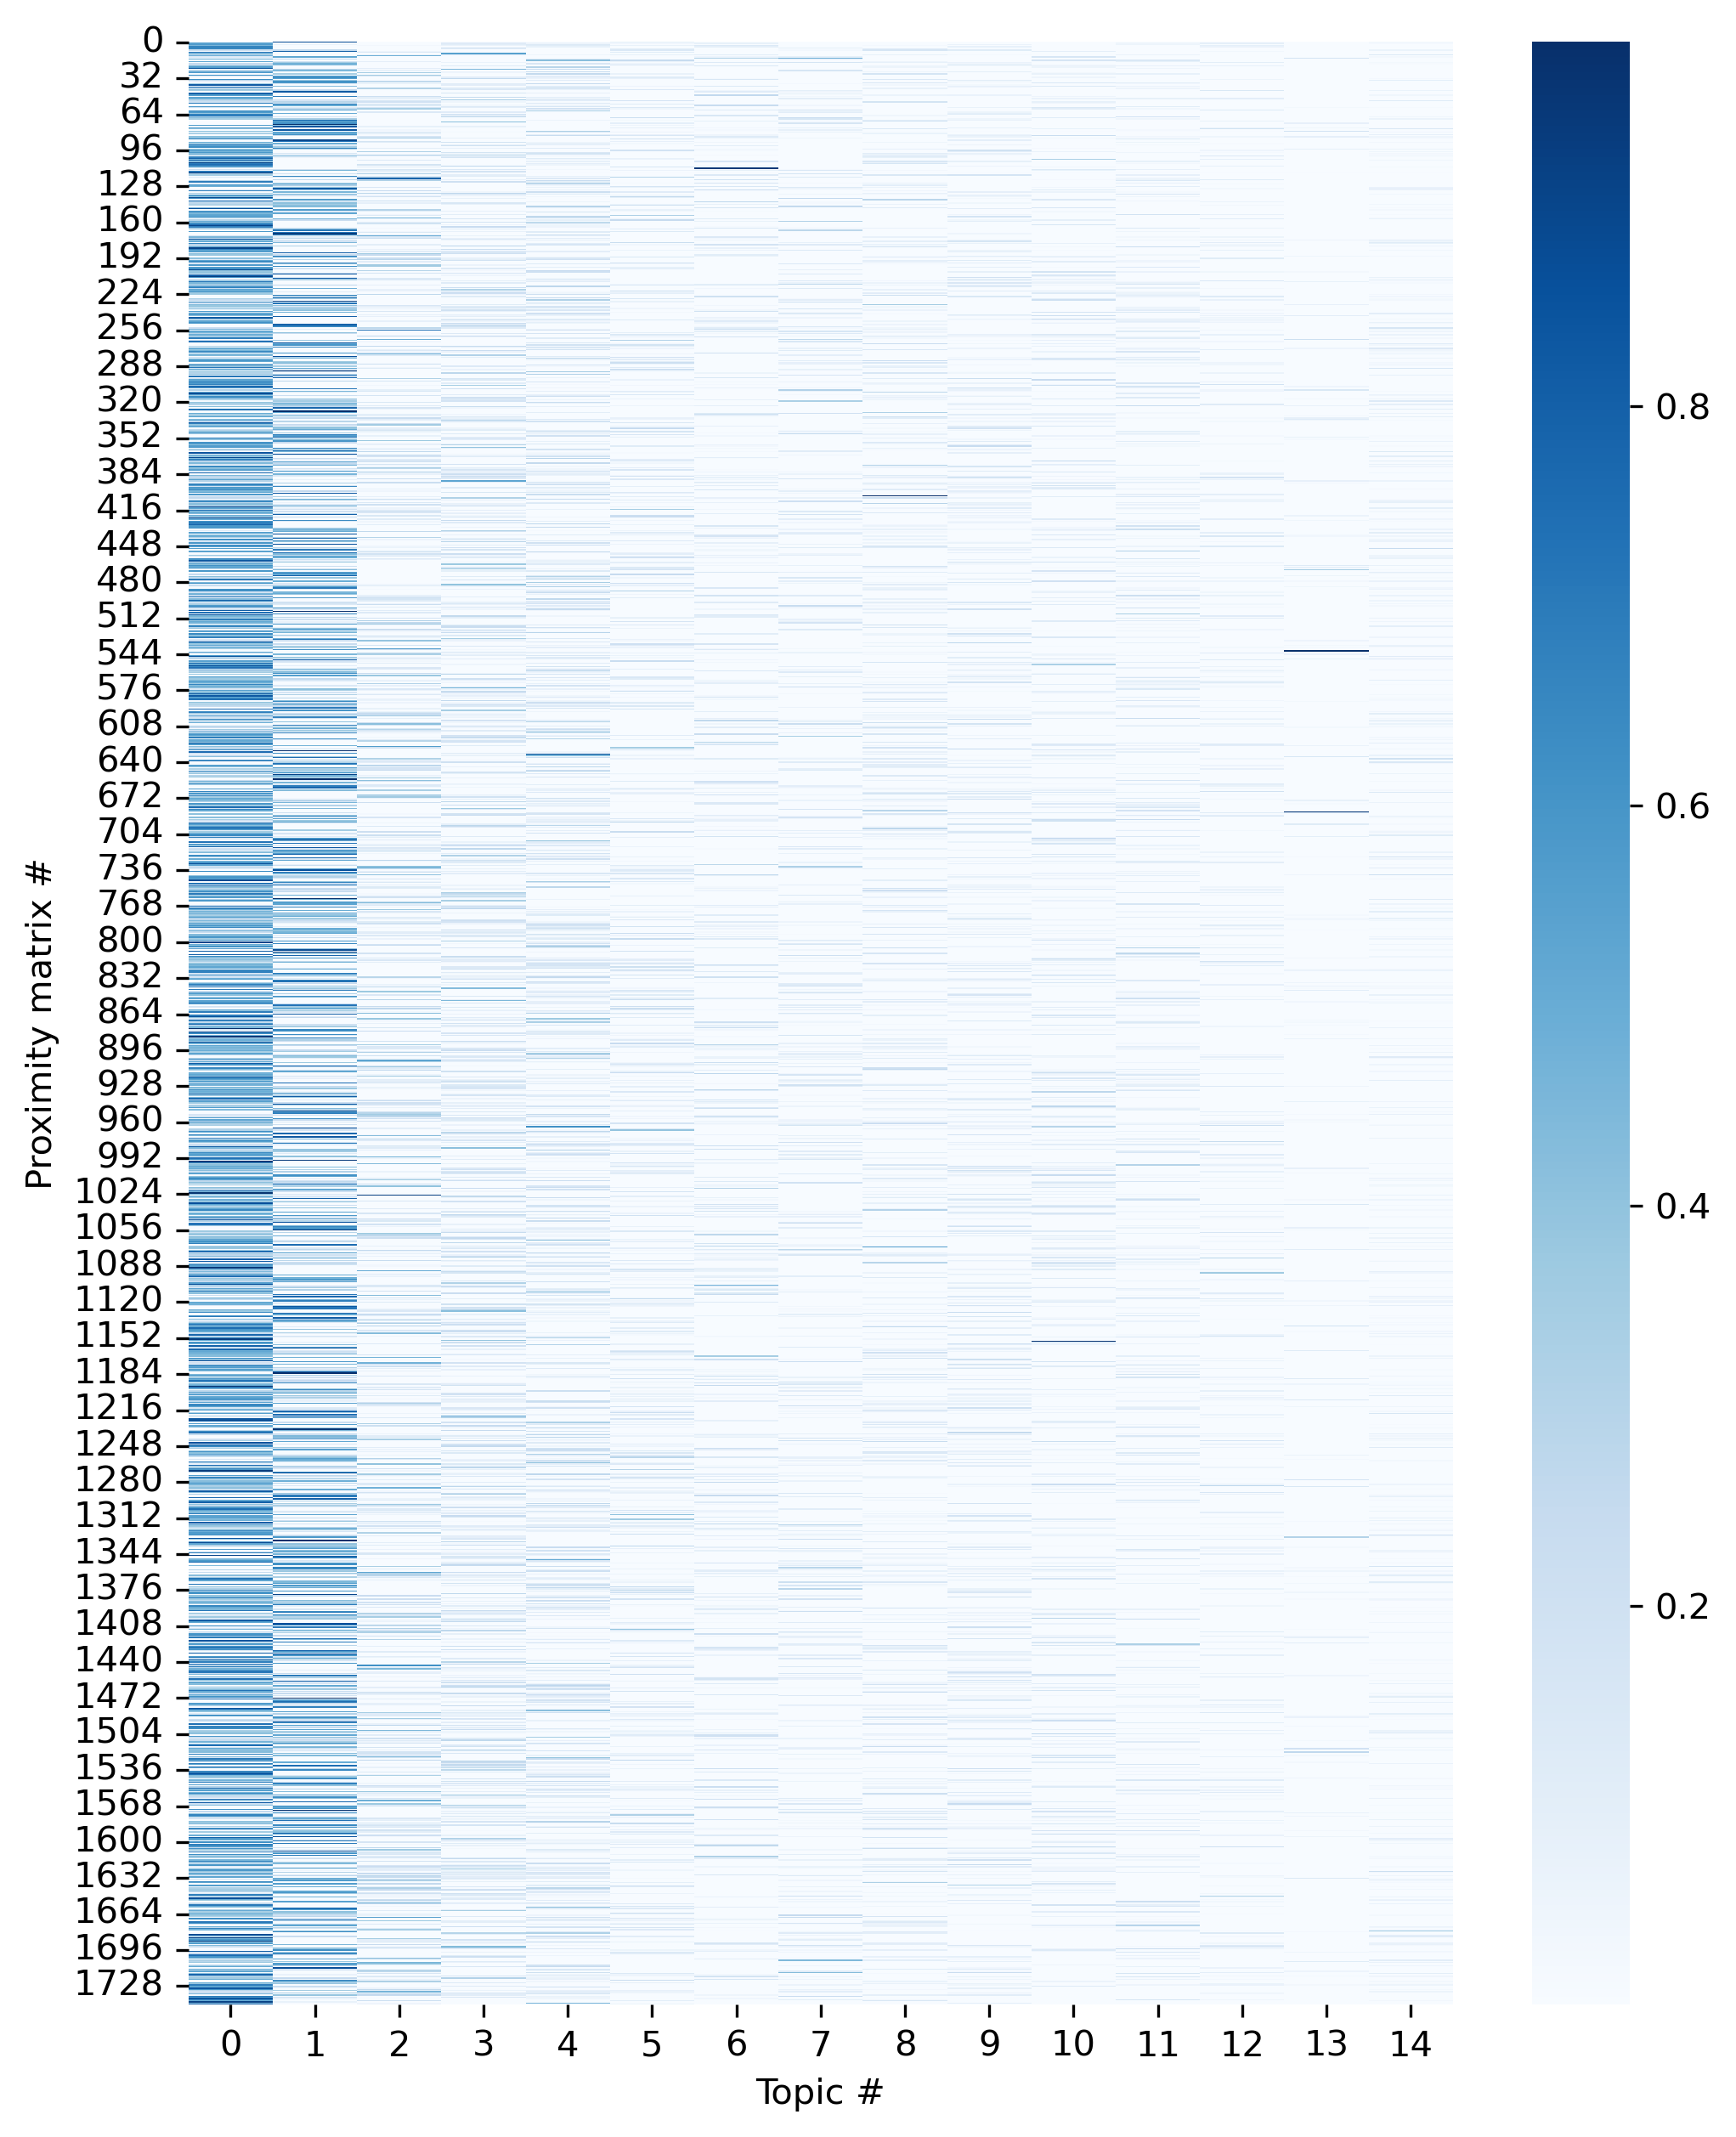

In [37]:
Image(filename="./results/10d822/decomposition.png", width=600, height=1600)